In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)


In [ ]:
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")

In [ ]:
series = df["Passengers"].astype(float)

In [ ]:
print(df.head())

            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121


In [ ]:
print("Total observations:", len(series))
print("Start date:", series.index.min())
print("End date:", series.index.max())

Total observations: 144
Start date: 1949-01-01 00:00:00
End date: 1960-12-01 00:00:00


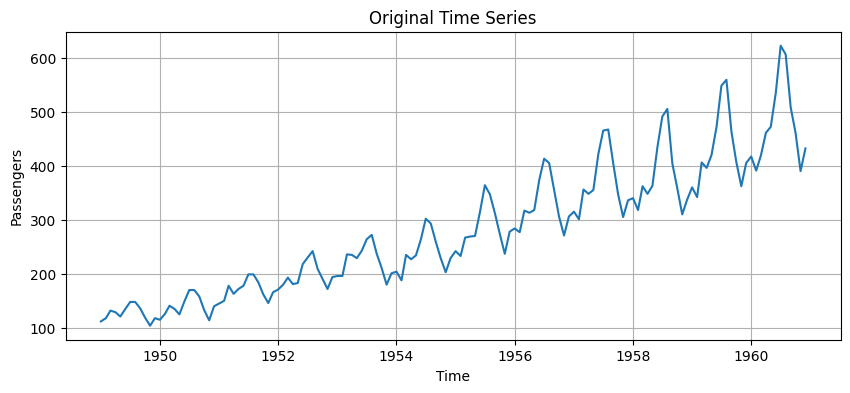

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(series)

plt.title("Original Time Series")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.grid()
plt.show()

In [ ]:
adf_result = adfuller(series)

print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])

ADF statistic: 0.8153688792060498
p-value: 0.991880243437641


/tmp/ipykernel_1302/3764505605.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)


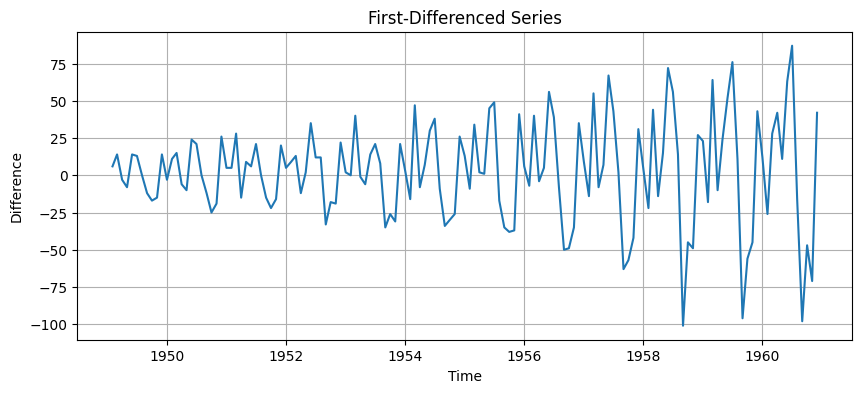

In [ ]:
diff_series = series.diff().dropna()

plt.figure(figsize=(10, 4))
plt.plot(diff_series)

plt.title("First-Differenced Series")
plt.xlabel("Time")
plt.ylabel("Difference")
plt.grid()
plt.show()

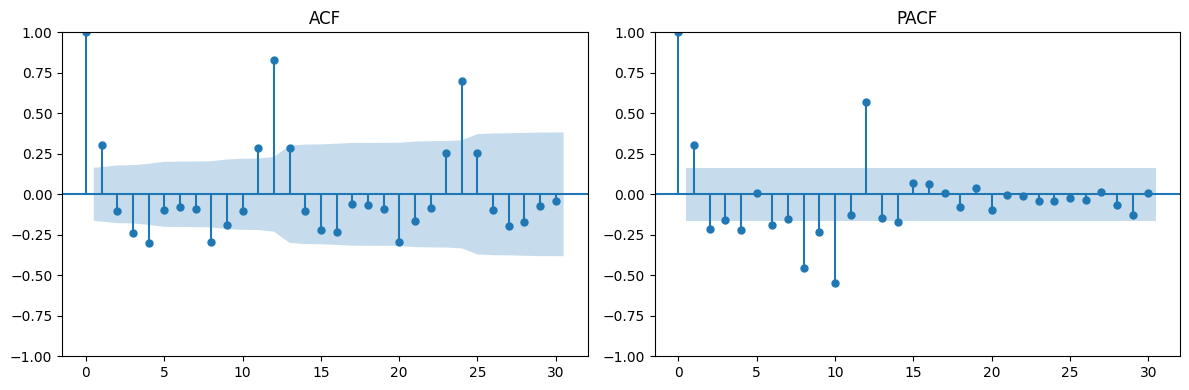

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(diff_series, ax=axes[0], lags=30)
plot_pacf(diff_series, ax=axes[1], lags=30, method="ywm")

axes[0].set_title("ACF")
axes[1].set_title("PACF")

plt.tight_layout()
plt.show()

In [ ]:
train_size = int(len(series) * 0.80)

train = series.iloc[:train_size]
test = series.iloc[train_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 115
Testing observations: 29


In [ ]:
model = ARIMA(train, order=(2, 1, 2))
model_fit = model.fit()

print(model_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -523.758
Date:                Thu, 29 Oct 2026   AIC                           1057.516
Time:                        16:20:57   BIC                           1071.197
Sample:                    01-01-1949   HQIC                          1063.069
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3280      0.145      2.268      0.023       0.045       0.611
ar.L2          0.2521      0.165      1.528      0.126      -0.071       0.575
ma.L1         -0.0125      0.109     -0.114      0.9

In [ ]:
forecast = model_fit.forecast(steps=len(test))

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 63.54531127532635
RMSE: 82.51301130378361


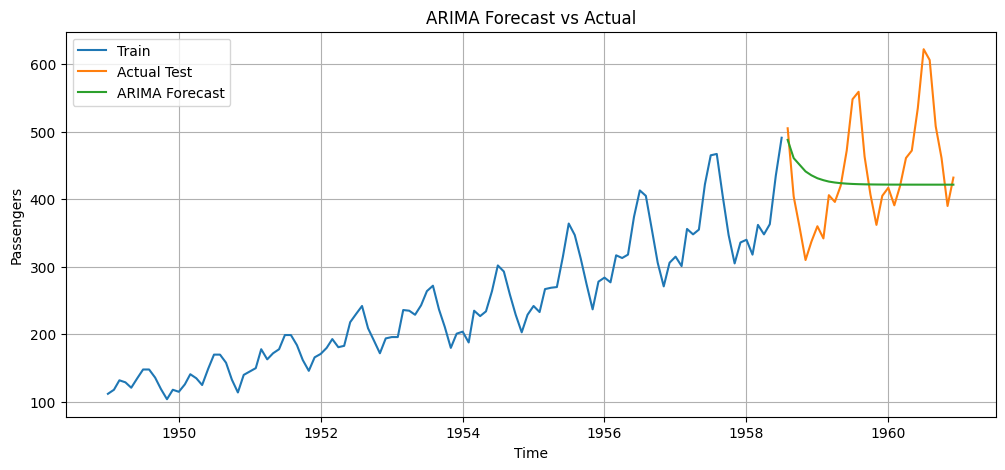

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Actual Test")
plt.plot(test.index, forecast, label="ARIMA Forecast")

plt.title("ARIMA Forecast vs Actual")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

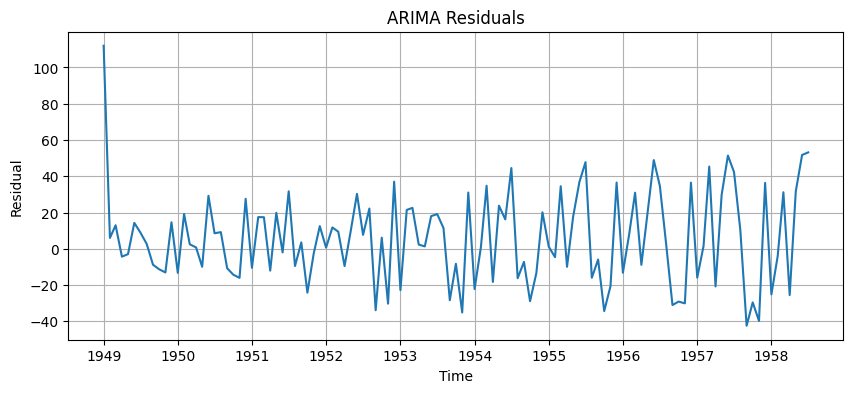

In [ ]:
residuals = model_fit.resid

plt.figure(figsize=(10, 4))
plt.plot(residuals)

plt.title("ARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid()
plt.show()

In [ ]:
# Task 4.1: Compare different ARIMA orders

orders = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2)
]

results = []

for order in orders:
    model = ARIMA(train, order=order)
    model_fit = model.fit()

    forecast = model_fit.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results.append({
        "ARIMA Order": str(order),
        "AIC": round(model_fit.aic, 3),
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3)
    })

results_df = pd.DataFrame(results)

print(results_df)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_date

  ARIMA Order       AIC     MAE    RMSE
0   (1, 1, 1)  1058.246  85.254  97.500
1   (2, 1, 1)  1058.648  60.529  82.621
2   (1, 1, 2)  1057.328  62.063  82.636
3   (2, 1, 2)  1057.516  63.545  82.513


In [ ]:
df = df.asfreq("MS")

In [ ]:
# Task 4.2: Effect of differencing

orders = [(2, 0, 2), (2, 1, 2)]
results_d = []

for order in orders:
    model = ARIMA(train, order=order)
    model_fit = model.fit()

    forecast = model_fit.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results_d.append({
        "ARIMA Order": str(order),
        "AIC": round(model_fit.aic, 3),
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3)
    })

results_d_df = pd.DataFrame(results_d)
print(results_d_df)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros 

  ARIMA Order       AIC     MAE     RMSE
0   (2, 0, 2)  1074.541  92.241  114.887
1   (2, 1, 2)  1057.516  63.545   82.513


In [ ]:
# Task 4.3: Compare forecast horizons

horizons = [6, 12, 24]
horizon_results = []

for h in horizons:
    forecast = model_fit.forecast(steps=h)

    # Compare with the corresponding actual test observations
    actual = test.iloc[:h]
    predicted = forecast.iloc[:h]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    horizon_results.append({
        "Forecast Horizon (Months)": h,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3)
    })

horizon_df = pd.DataFrame(horizon_results)
print(horizon_df)

   Forecast Horizon (Months)     MAE    RMSE
0                          6  77.787  85.581
1                         12  64.982  76.775
2                         24  62.103  79.919


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<Figure size 1000x400 with 0 Axes>

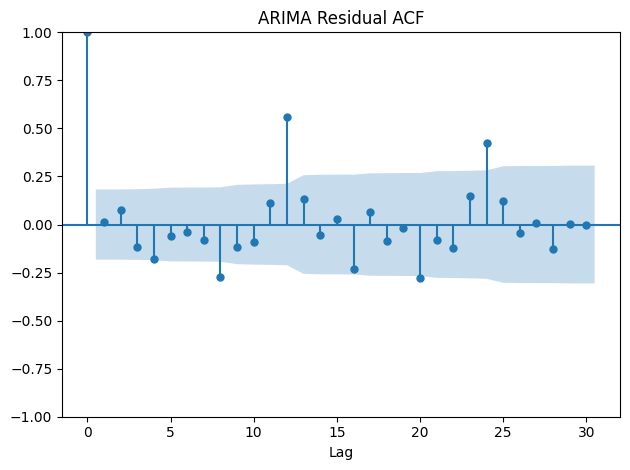

In [ ]:
# Task 4.4: Residual ACF

# Fit the main ARIMA(2,1,2) model
arima_model = ARIMA(train, order=(2, 1, 2)).fit()

# Extract residuals
residuals = arima_model.resid

# Plot residual ACF
plt.figure(figsize=(10, 4))
plot_acf(residuals.dropna(), lags=30)

plt.title("ARIMA Residual ACF")
plt.xlabel("Lag")
plt.tight_layout()
plt.show()